In [1]:
import tensorflow as tf
import os

os.chdir('/home/maria-luna')

train_ds = tf.keras.utils.image_dataset_from_directory(
    'dataset/train',
    image_size=(224, 224),
    batch_size=16,
    label_mode='categorical',
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    'dataset/val',
    image_size=(224, 224),
    batch_size=16,
    label_mode='categorical',
    shuffle=False
)

clases = train_ds.class_names
print("Clases:", clases)
print("Batches train:", len(train_ds))
print("Batches val:", len(val_ds))

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds   = val_ds.prefetch(tf.data.AUTOTUNE)

I0000 00:00:1780976824.902322   13146 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1780976824.958203   13146 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1780976826.941119   13146 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Found 922 files belonging to 5 classes.
Found 261 files belonging to 5 classes.
Clases: ['capacitor', 'diodo', 'led', 'resistencia', 'transistor']
Batches train: 58
Batches val: 17


E0000 00:00:1780976828.954269   13146 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [2]:
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

base_model = tf.keras.applications.EfficientNetB0(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = layers.RandomRotation(0.2)(inputs)
x = layers.RandomFlip("horizontal")(x)
x = layers.RandomZoom(0.15)(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(len(clases), activation='softmax')(x)

model = tf.keras.Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
print("✓ Modelo listo")

✓ Modelo listo


In [3]:
callbacks = [
    EarlyStopping(patience=7, restore_best_weights=True, verbose=1),
    ModelCheckpoint('mejor_modelo.keras', save_best_only=True, verbose=1)
]

history = model.fit(
    train_ds,
    epochs=30,
    validation_data=val_ds,
    callbacks=callbacks,
    verbose=1
)
print("✓ Entrenamiento completo")

Epoch 1/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 509ms/step - accuracy: 0.2754 - loss: 1.6262
Epoch 1: val_loss improved from None to 1.10002, saving model to mejor_modelo.keras

Epoch 1: finished saving model to mejor_modelo.keras
58/58 ━━━━━━━━━━━━━━━━━━━━ 49s 692ms/step - accuracy: 0.3774 - loss: 1.4882 - val_accuracy: 0.6513 - val_loss: 1.1000
Epoch 2/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 507ms/step - accuracy: 0.5874 - loss: 1.1059
Epoch 2: val_loss improved from 1.10002 to 0.94454, saving model to mejor_modelo.keras

Epoch 2: finished saving model to mejor_modelo.keras
58/58 ━━━━━━━━━━━━━━━━━━━━ 41s 698ms/step - accuracy: 0.5900 - loss: 1.0983 - val_accuracy: 0.6858 - val_loss: 0.9445
Epoch 3/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 557ms/step - accuracy: 0.6376 - loss: 0.9586
Epoch 3: val_loss improved from 0.94454 to 0.85971, saving model to mejor_modelo.keras

Epoch 3: finished saving model to mejor_modelo.keras
58/58 ━━━━━━━━━━━━━━━━━━━━ 43s 748ms/step - accuracy: 0.6410 - loss: 0.9617 - val_accu

In [4]:
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00005),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_ft = [
    EarlyStopping(patience=5, restore_best_weights=True, verbose=1),
    ModelCheckpoint('mejor_modelo_ft.keras', save_best_only=True, verbose=1)
]

print("Iniciando fine-tuning...")
history_ft = model.fit(
    train_ds,
    epochs=20,
    validation_data=val_ds,
    callbacks=callbacks_ft,
    verbose=1
)
print("✓ Fine-tuning completo")

Iniciando fine-tuning...
Epoch 1/20
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 650ms/step - accuracy: 0.6918 - loss: 0.8035
Epoch 1: val_loss improved from None to 0.51082, saving model to mejor_modelo_ft.keras

Epoch 1: finished saving model to mejor_modelo_ft.keras
58/58 ━━━━━━━━━━━━━━━━━━━━ 63s 880ms/step - accuracy: 0.7202 - loss: 0.7465 - val_accuracy: 0.8467 - val_loss: 0.5108
Epoch 2/20
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 625ms/step - accuracy: 0.7978 - loss: 0.5872
Epoch 2: val_loss did not improve from 0.51082
58/58 ━━━━━━━━━━━━━━━━━━━━ 47s 805ms/step - accuracy: 0.7896 - loss: 0.6080 - val_accuracy: 0.8314 - val_loss: 0.5164
Epoch 3/20
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 616ms/step - accuracy: 0.8164 - loss: 0.5768
Epoch 3: val_loss did not improve from 0.51082
58/58 ━━━━━━━━━━━━━━━━━━━━ 79s 760ms/step - accuracy: 0.8200 - loss: 0.5333 - val_accuracy: 0.8161 - val_loss: 0.5362
Epoch 4/20
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 603ms/step - accuracy: 0.7977 - loss: 0.5220
Epoch 4: val_loss did not improve from 

In [5]:
callbacks = [
    EarlyStopping(patience=7, restore_best_weights=True, verbose=1),
    ModelCheckpoint('mejor_modelo.keras', save_best_only=True, verbose=1)
]

history = model.fit(
    train_ds,
    epochs=30,
    validation_data=val_ds,
    callbacks=callbacks,
    verbose=1
)

print("✓ Entrenamiento completo")

Epoch 1/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 610ms/step - accuracy: 0.7647 - loss: 0.6892
Epoch 1: val_loss improved from None to 0.52446, saving model to mejor_modelo.keras

Epoch 1: finished saving model to mejor_modelo.keras
58/58 ━━━━━━━━━━━━━━━━━━━━ 47s 803ms/step - accuracy: 0.7809 - loss: 0.6181 - val_accuracy: 0.8314 - val_loss: 0.5245
Epoch 2/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 594ms/step - accuracy: 0.8029 - loss: 0.5599
Epoch 2: val_loss did not improve from 0.52446
58/58 ━━━━━━━━━━━━━━━━━━━━ 42s 730ms/step - accuracy: 0.7950 - loss: 0.5658 - val_accuracy: 0.8238 - val_loss: 0.5329
Epoch 3/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 602ms/step - accuracy: 0.8302 - loss: 0.5072
Epoch 3: val_loss did not improve from 0.52446
58/58 ━━━━━━━━━━━━━━━━━━━━ 83s 744ms/step - accuracy: 0.8200 - loss: 0.5170 - val_accuracy: 0.8161 - val_loss: 0.5417
Epoch 4/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 661ms/step - accuracy: 0.8152 - loss: 0.4835
Epoch 4: val_loss did not improve from 0.52446
58/58 ━━━━━━━━━━━━━━━━━

In [6]:
# Descongelar las últimas 20 capas de la base
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Recompilar con learning rate más pequeño
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00005),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_ft = [
    EarlyStopping(patience=5, restore_best_weights=True, verbose=1),
    ModelCheckpoint('mejor_modelo_ft.keras', save_best_only=True, verbose=1)
]

print("Iniciando fine-tuning...")
history_ft = model.fit(
    train_ds,
    epochs=20,
    validation_data=val_ds,
    callbacks=callbacks_ft,
    verbose=1
)

print("✓ Fine-tuning completo")

Iniciando fine-tuning...
Epoch 1/20
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 649ms/step - accuracy: 0.9108 - loss: 0.2662
Epoch 1: val_loss improved from None to 0.44779, saving model to mejor_modelo_ft.keras

Epoch 1: finished saving model to mejor_modelo_ft.keras
58/58 ━━━━━━━━━━━━━━━━━━━━ 61s 867ms/step - accuracy: 0.9219 - loss: 0.2453 - val_accuracy: 0.8774 - val_loss: 0.4478
Epoch 2/20
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 675ms/step - accuracy: 0.9211 - loss: 0.2176
Epoch 2: val_loss did not improve from 0.44779
58/58 ━━━━━━━━━━━━━━━━━━━━ 48s 829ms/step - accuracy: 0.9208 - loss: 0.2305 - val_accuracy: 0.8736 - val_loss: 0.4506
Epoch 3/20
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 655ms/step - accuracy: 0.9165 - loss: 0.2356
Epoch 3: val_loss did not improve from 0.44779
58/58 ━━━━━━━━━━━━━━━━━━━━ 80s 800ms/step - accuracy: 0.9328 - loss: 0.2168 - val_accuracy: 0.8774 - val_loss: 0.4498
Epoch 4/20
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 633ms/step - accuracy: 0.9428 - loss: 0.2041
Epoch 4: val_loss improved from 0.44779

Found 270 files belonging to 5 classes.


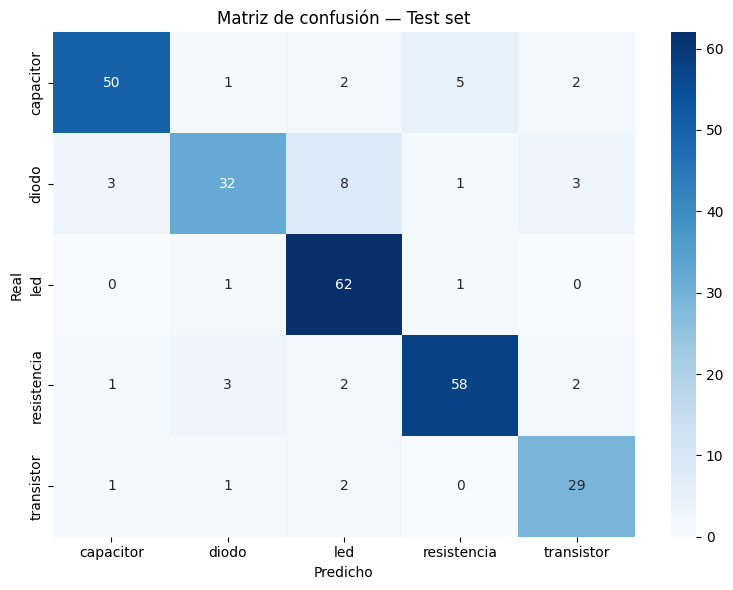


               precision    recall  f1-score   support

   capacitor       0.91      0.83      0.87        60
       diodo       0.84      0.68      0.75        47
         led       0.82      0.97      0.89        64
 resistencia       0.89      0.88      0.89        66
  transistor       0.81      0.88      0.84        33

    accuracy                           0.86       270
   macro avg       0.85      0.85      0.85       270
weighted avg       0.86      0.86      0.85       270



In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Cargar el mejor modelo
mejor_modelo = tf.keras.models.load_model('mejor_modelo_ft.keras')

# Predecir en el conjunto de test
test_ds = tf.keras.utils.image_dataset_from_directory(
    '/home/maria-luna/dataset/test',
    image_size=(224, 224),
    batch_size=16,
    label_mode='categorical',
    shuffle=False
)

y_true, y_pred = [], []
for imgs, labels in test_ds:
    preds = mejor_modelo.predict(imgs, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

# Matriz de confusión
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=clases, yticklabels=clases)
plt.title('Matriz de confusión — Test set')
plt.ylabel('Real')
plt.xlabel('Predicho')
plt.tight_layout()
plt.savefig('matriz_confusion.png', dpi=100)
plt.show()

# Reporte detallado
print("\n", classification_report(y_true, y_pred, target_names=clases))

In [9]:
from PIL import Image
import numpy as np

def predecir_componente(ruta_imagen):
    img = Image.open(ruta_imagen).convert('RGB').resize((224, 224))
    arr = np.array(img, dtype=np.float32)
    arr = np.expand_dims(arr, axis=0)
    
    pred = mejor_modelo.predict(arr, verbose=0)
    idx = np.argmax(pred)
    confianza = pred[0][idx] * 100
    
    print(f"Componente: {clases[idx].upper()}")
    print(f"Confianza:  {confianza:.1f}%")
    print()
    for i, c in enumerate(clases):
        barra = '█' * int(pred[0][i] * 30)
        print(f"  {c:12} {pred[0][i]*100:5.1f}% {barra}")
    
    return clases[idx]

# Prueba con una imagen del test set
import os
test_img = '/home/maria-luna/dataset/test/led/' + os.listdir('/home/maria-luna/dataset/test/led/')[0]
print(f"Imagen: {test_img}\n")
predecir_componente(test_img)

Imagen: /home/maria-luna/dataset/test/led/000014.jpg

Componente: LED
Confianza:  97.8%

  capacitor      0.0% 
  diodo          0.6% 
  led           97.8% █████████████████████████████
  resistencia    1.2% 
  transistor     0.3% 


'led'

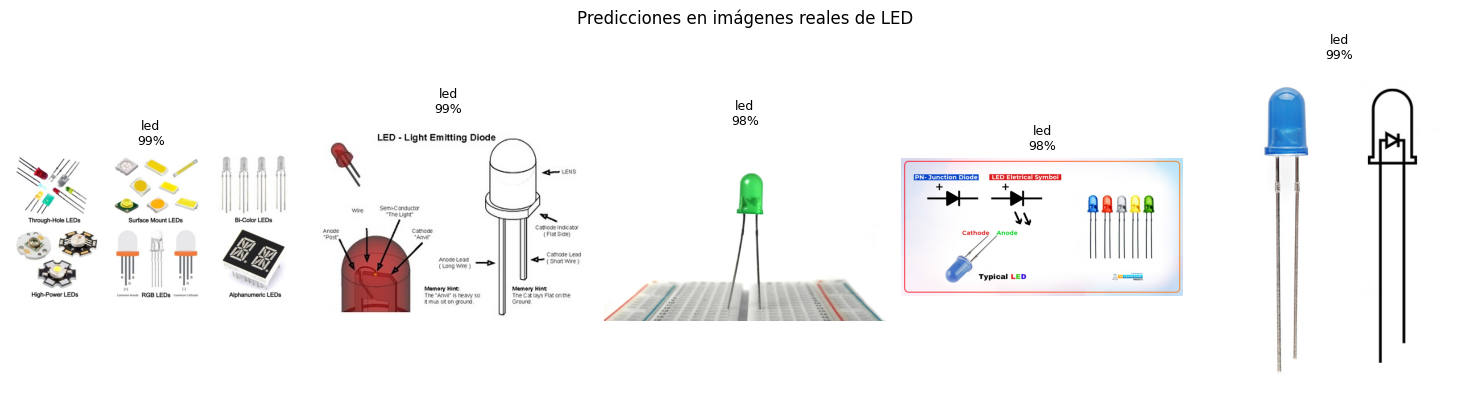

In [11]:
import os
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# 1. Obtener la ruta de la carpeta de LEDs en test
carpeta_leds = '/home/maria-luna/dataset/test/led/'

# 2. Leer automáticamente los archivos reales que hay dentro de la carpeta
archivos_reales = sorted(os.listdir(carpeta_leds))
# Filtrar para asegurarnos de que solo agarre archivos de imagen (.jpg, .jpeg, .png)
imagenes_reales = [f for f in archivos_reales if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

# 3. Tomar las primeras 5 imágenes que existan en TU carpeta
imagenes_prueba = imagenes_reales[:5]

# Validar si tienes al menos 5 imágenes para mostrar
if len(imagenes_prueba) < 5:
    print(f"⚠️ Nota: Solo se encontraron {len(imagenes_prueba)} imágenes en la carpeta.")
    fig, axes = plt.subplots(1, len(imagenes_prueba), figsize=(15, 4))
    if len(imagenes_prueba) == 1: axes = [axes] # Asegurar que sea iterable si es solo una
else:
    fig, axes = plt.subplots(1, 5, figsize=(15, 4))

# 4. Hacer las predicciones y graficar
for i, fname in enumerate(imagenes_prueba):
    ruta = os.path.join(carpeta_leds, fname)
    img = Image.open(ruta).convert('RGB')
    pred = mejor_modelo.predict(np.expand_dims(np.array(img.resize((224,224)), dtype=np.float32), axis=0), verbose=0)
    clase_pred = clases[np.argmax(pred)]
    confianza = np.max(pred) * 100
    
    axes[i].imshow(img)
    axes[i].set_title(f'{clase_pred}\n{confianza:.0f}%', fontsize=9)
    axes[i].axis('off')

plt.suptitle('Predicciones en imágenes reales de LED', fontsize=12)
plt.tight_layout()
plt.show()

In [12]:
import shutil, random, os
from pathlib import Path

# Limpiar dataset anterior
if os.path.exists('/home/maria-luna/dataset'):
    shutil.rmtree('/home/maria-luna/dataset')

def dividir_dataset(src, dst, ratios=(0.70, 0.15, 0.15), seed=42):
    random.seed(seed)
    splits = ['train', 'val', 'test']
    for clase in Path(src).iterdir():
        if not clase.is_dir():
            continue
        imagenes = list(clase.glob('*.jpg')) + list(clase.glob('*.png')) + list(clase.glob('*.jpeg'))
        random.shuffle(imagenes)
        n = len(imagenes)
        c1 = int(n * ratios[0])
        c2 = int(n * (ratios[0] + ratios[1]))
        grupos = [imagenes[:c1], imagenes[c1:c2], imagenes[c2:]]
        for split, grupo in zip(splits, grupos):
            destino = Path(dst) / split / clase.name
            destino.mkdir(parents=True, exist_ok=True)
            for img in grupo:
                shutil.copy(img, destino / img.name)
        print(f"{clase.name:15} → train: {len(grupos[0])} | val: {len(grupos[1])} | test: {len(grupos[2])}")

dividir_dataset('/home/maria-luna/raw/', '/home/maria-luna/dataset/')
print("\n✓ Dataset listo")

transistor      → train: 72 | val: 16 | test: 16
diodo           → train: 72 | val: 16 | test: 16
resistencia     → train: 72 | val: 16 | test: 16
capacitor       → train: 72 | val: 16 | test: 16
led             → train: 72 | val: 16 | test: 16

✓ Dataset listo
